# 05 — Guess hidden fatigue and plan with QMDP

**Goal:** track uncertainty about the teacher and decide with future consequences in mind. A **belief** gives probabilities for fatigue levels 0–4. **Myopic** means choose only for immediate reward. **QMDP** adds future value but optimistically assumes the hidden state becomes known after the current step. Code: [belief.py](../src/control/belief.py), [qmdp.py](../src/control/qmdp.py).

Ordinary correctness is hidden. We use response time and known-answer gold checks as clues. The response-time likelihood includes a mixture of correct and wrong answers. Observe the current state first, update the belief, then predict the next fatigue state.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run, load_calibration, load_contexts
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Prepare the population planning model

In [2]:
assert json.loads((project / 'outputs/sim_validation/gate.json').read_text())['passed']
from src.sim.fatigue import Scenario
from src.eval.stage1 import PlanningModel, population_model, benchmark, summarize, run_policy
from src.eval.stats import paired_difference
contexts = load_contexts()
scenario = Scenario(beta=2)
model = PlanningModel(contexts, scenario, population_model(load_calibration()))
folder = save_run('notebook05', {'scenario': scenario.dictionary(), 'episodes': 500})

## 2. Look at a few hidden-state tracking examples
True fatigue is shown only in evaluation plots. It never enters the QMDP policy.
Baselines use population speed estimates, not the person's private response-time baseline.
Consequently these clues are imperfect even when the fatigue family is correctly specified.

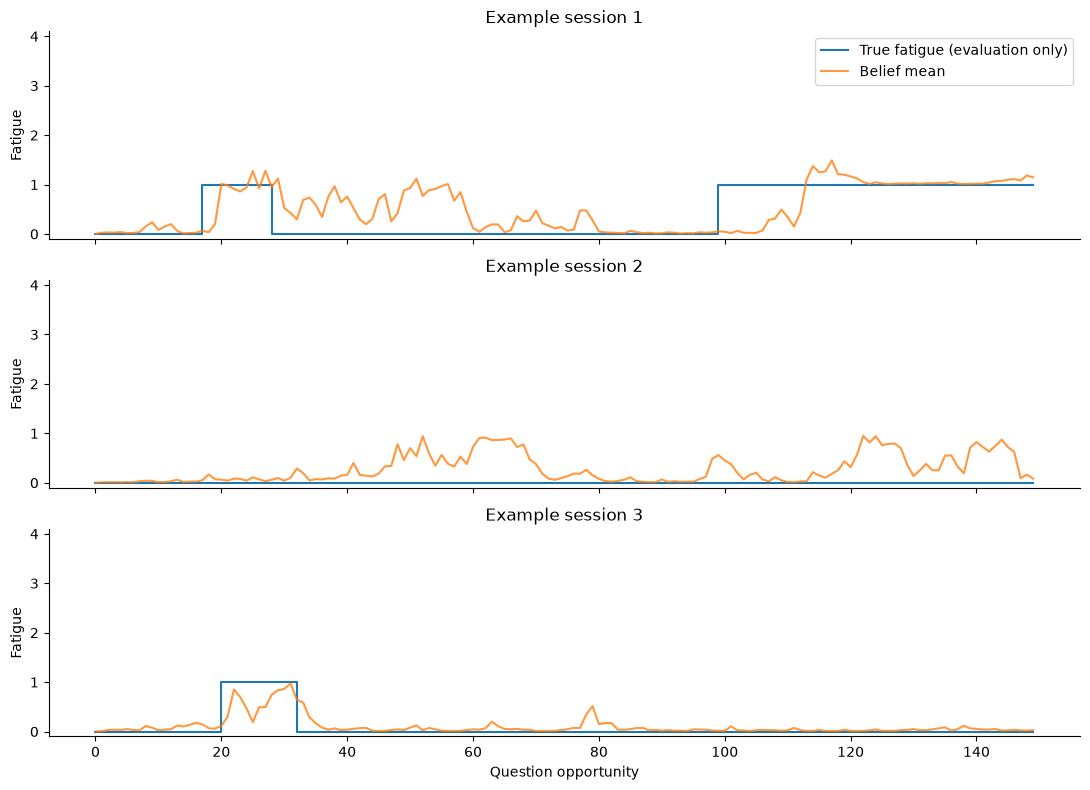

In [3]:
demonstration = run_policy(contexts, scenario, 'qmdp', episodes=5, model=model, trace=True)
trace = demonstration['trace']
trace.to_csv(folder / 'tracking_examples.csv', index=False)
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for episode, ax in enumerate(axes):
    person = trace[trace.episode == episode]
    ax.step(person.step, person.fatigue, where='post', label='True fatigue (evaluation only)')
    ax.plot(person.step, person.estimated_fatigue, label='Belief mean', alpha=.8)
    ax.set(ylabel='Fatigue', ylim=(-.1, 4.1), title=f'Example session {episode + 1}')
axes[0].legend()
axes[-1].set_xlabel('Question opportunity')
show_plot('01_hidden_fatigue_tracking')

## 3. Compare fixed rules, greedy decisions, and planning
The oracle is a fatigue-visible approximate-planning reference. It is not a mathematical optimality bound.

,reward,information,seconds,error_rate,tracking_error,bits_per_second,reward_se
policy,,,,,,,
oracle,7.614,196.080,188.465,0.035,0.139,1.040,3.054
qmdp,-7.396,169.097,176.492,0.042,0.200,0.958,3.176
verify,-20.513,111.271,131.785,0.041,0.142,0.844,3.064
myopic,-50.285,159.305,209.590,0.068,0.209,0.760,4.538
blind,-323.322,201.337,524.660,0.223,0.228,0.384,16.605
full,-793.434,203.847,997.281,0.477,0.246,0.204,29.038


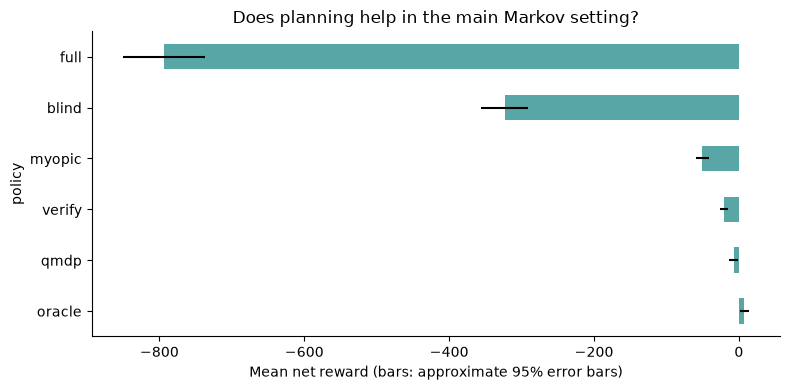

In [4]:
policies = ['full', 'verify', 'blind', 'myopic', 'qmdp', 'oracle']
table, path = benchmark(contexts, scenario, policies, episodes=500)
summary = summarize(table)
display(summary.round(3))
summary.reward.plot.barh(xerr=summary.reward_se * 1.96, color='#58a6a6')
plt.xlabel('Mean net reward (bars: approximate 95% error bars)')
plt.title('Does planning help in the main Markov setting?')
show_plot('02_qmdp_comparison')

## 4. Check paired differences
Subtract two policies' scores within each matched session. Bootstrap resamples those differences to show uncertainty. A confidence interval fully above zero favours QMDP.
These are development comparisons; they are not final held-out claims.

,first,second,difference,ci_low,ci_high
0,qmdp,verify,13.118,8.749,17.411
1,qmdp,blind,315.927,286.338,345.621
2,qmdp,myopic,42.889,37.081,48.944


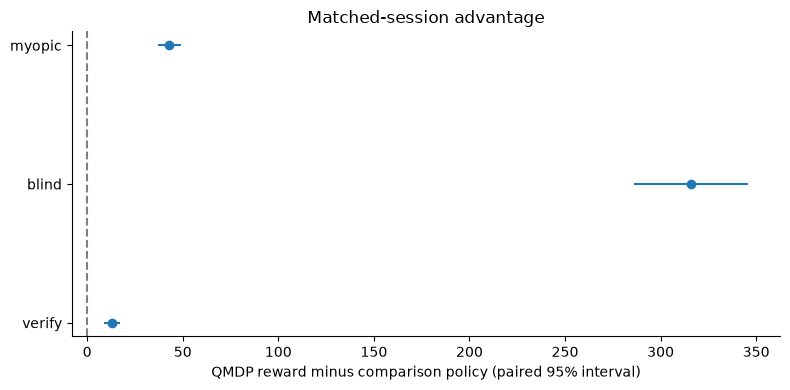

In [5]:
comparisons = pd.DataFrame([paired_difference(table, 'qmdp', other) for other in ['verify', 'blind', 'myopic']])
comparisons.to_csv(folder / 'paired_comparisons.csv', index=False)
display(comparisons.round(3))
plt.errorbar(comparisons.difference, comparisons.second,
    xerr=np.array([comparisons.difference - comparisons.ci_low, comparisons.ci_high - comparisons.difference]), fmt='o')
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('QMDP reward minus comparison policy (paired 95% interval)')
plt.title('Matched-session advantage')
show_plot('03_paired_advantages')

## 5. See the questions QMDP chooses
The pattern is diagnostic: true fatigue labels appear only after the experiment for plotting.

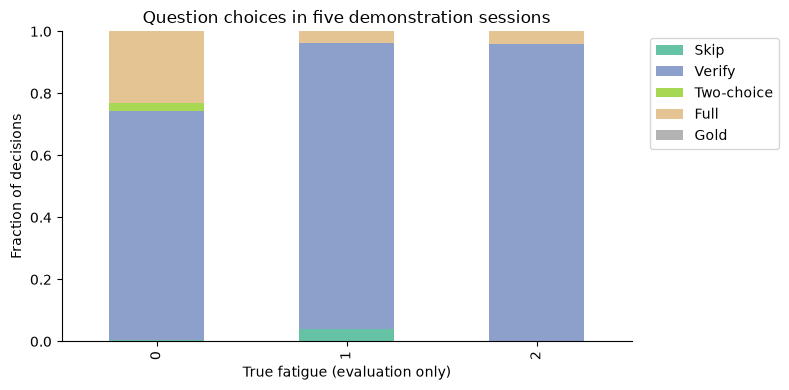

In [6]:
action_mix = pd.crosstab(trace.fatigue.round().astype(int), trace.action, normalize='index').reindex(columns=range(5), fill_value=0)
action_mix.columns = ['Skip', 'Verify', 'Two-choice', 'Full', 'Gold']
action_mix.plot.bar(stacked=True, colormap='Set2')
plt.ylabel('Fraction of decisions')
plt.xlabel('True fatigue (evaluation only)')
plt.title('Question choices in five demonstration sessions')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_plot('04_qmdp_action_mix')

## 6. Run the experiment-boundary checks
These check channel probabilities, observation timing, zero-fatigue behaviour, and controller access to private simulator state.

In [7]:
import subprocess
checks = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
    cwd=project, capture_output=True, text=True)
print(checks.stdout + checks.stderr)
assert checks.returncode == 0, 'Fix experiment-boundary failures before continuing.'

test_answer_count_mode_is_unchanged (test_lapse_seconds.LapseSecondsChecks.test_answer_count_mode_is_unchanged) ... ok
test_onset_draw_is_shared_across_policies (test_lapse_seconds.LapseSecondsChecks.test_onset_draw_is_shared_across_policies) ... ok
test_pauses_count_as_time_only_in_seconds_mode (test_lapse_seconds.LapseSecondsChecks.test_pauses_count_as_time_only_in_seconds_mode) ... ok
test_seconds_mode_starts_at_its_scheduled_second (test_lapse_seconds.LapseSecondsChecks.test_seconds_mode_starts_at_its_scheduled_second) ... ok
test_stage1_case_lists (test_lapse_seconds.LapseSecondsChecks.test_stage1_case_lists) ... ok
test_stage2_case_lists (test_lapse_seconds.LapseSecondsChecks.test_stage2_case_lists) ... ok
test_stage2_onset_range_reaches_every_shift (test_lapse_seconds.LapseSecondsChecks.test_stage2_onset_range_reaches_every_shift) ... ok
test_deployable_planner_does_not_copy_the_true_world (test_review_fixes.ReviewFixChecks.test_deployable_planner_does_not_copy_the_true_world) .